Running Forward Chaining...

Query Result Substitution: {}

Deduction Path Edges:
  [Missile(M1)] ---(Missile => Weapon)---> [Weapon(M1)]
  [Enemy(Nono, America)] ---(Enemy => Hostile)---> [Hostile(Nono)]
  [Owns(Nono, M1)] ---(Owns & Missile => Sells)---> [Sells(West, M1, Nono)]
  [Missile(M1)] ---(Owns & Missile => Sells)---> [Sells(West, M1, Nono)]
  [American(West)] ---(American & Weapon & Sells & Hostile => Criminal)---> [Criminal(West)]
  [Weapon(M1)] ---(American & Weapon & Sells & Hostile => Criminal)---> [Criminal(West)]
  [Sells(West, M1, Nono)] ---(American & Weapon & Sells & Hostile => Criminal)---> [Criminal(West)]
  [Hostile(Nono)] ---(American & Weapon & Sells & Hostile => Criminal)---> [Criminal(West)]


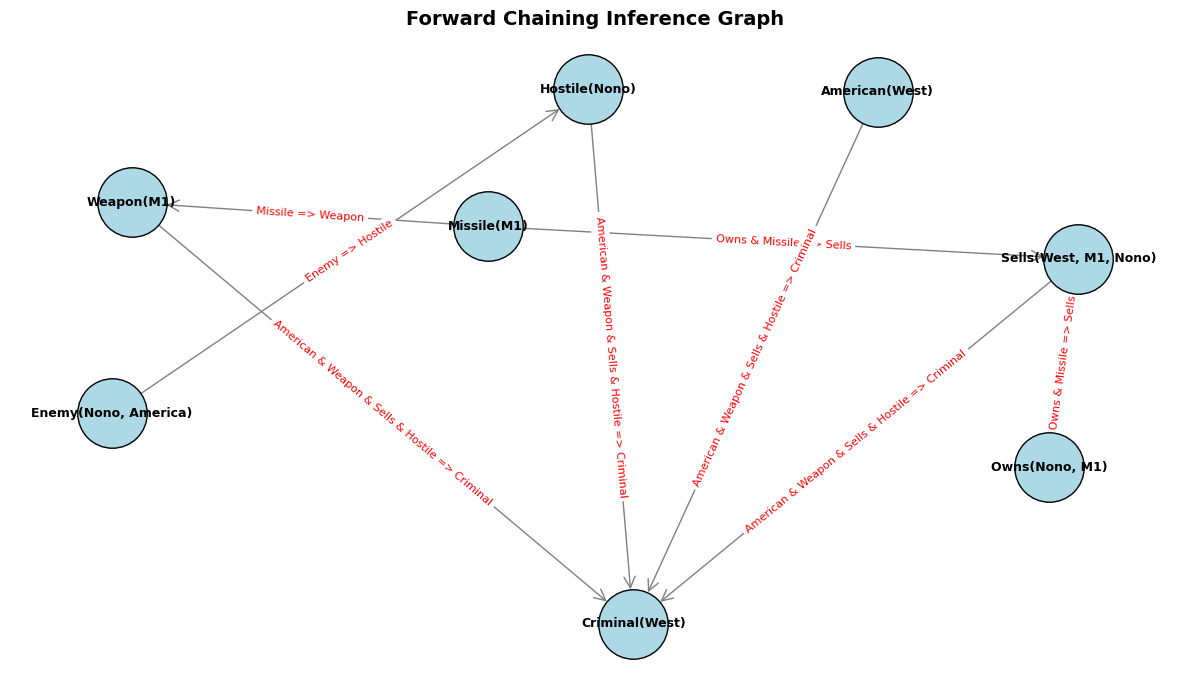

In [2]:
import re
import matplotlib.pyplot as plt
import networkx as nx

# --- FOL Representation & Helpers ---

class Variable:
    def __init__(self, name):
        self.name = name
    def __repr__(self):
        return f"?{self.name}"
    def __eq__(self, other):
        return isinstance(other, Variable) and self.name == other.name
    def __hash__(self):
        return hash(self.name)

class Expr:
    def __init__(self, op, *args):
        self.op = op
        self.args = tuple(args)
    def __repr__(self):
        if not self.args:
            return str(self.op)
        return f"{self.op}({', '.join(map(str, self.args))})"
    def __eq__(self, other):
        return isinstance(other, Expr) and self.op == other.op and self.args == other.args
    def __hash__(self):
        return hash((self.op, self.args))

class Clause:
    def __init__(self, body, head):
        self.body = body  # List of Expr
        self.head = head  # Single Expr
    def __repr__(self):
        if not self.body:
            return f"Fact: {self.head}"
        return f"{' & '.join(map(str, self.body))} => {self.head}"

def is_variable(x):
    return isinstance(x, Variable)

def subst(theta, expr):
    """Applies substitution theta to an expression."""
    if is_variable(expr):
        return theta.get(expr, expr)
    if isinstance(expr, Expr):
        return Expr(expr.op, *[subst(theta, arg) for arg in expr.args])
    return expr

def unify(x, y, theta=None):
    """Unifies expressions x and y under substitution theta."""
    if theta is None:
        theta = {}
    if theta is False:
        return False
    if x == y:
        return theta
    if is_variable(x):
        return unify_var(x, y, theta)
    if is_variable(y):
        return unify_var(y, x, theta)
    if isinstance(x, Expr) and isinstance(y, Expr):
        if x.op != y.op or len(x.args) != len(y.args):
            return False
        for ax, ay in zip(x.args, y.args):
            theta = unify(ax, ay, theta)
            if theta is False:
                return False
        return theta
    return False

def unify_var(var, val, theta):
    if var in theta:
        return unify(theta[var], val, theta)
    if val in theta:
        return unify(var, theta[val], theta)
    new_theta = theta.copy()
    new_theta[var] = val
    return new_theta

# --- Variable Standardizer ---
var_counter = 0
def standardize_variables(clause):
    global var_counter
    var_map = {}

    def collect_and_rename(expr):
        global var_counter
        if is_variable(expr):
            if expr not in var_map:
                var_counter += 1
                var_map[expr] = Variable(f"{expr.name}_{var_counter}")
            return var_map[expr]
        if isinstance(expr, Expr):
            return Expr(expr.op, *[collect_and_rename(arg) for arg in expr.args])
        return expr

    new_body = [collect_and_rename(b) for b in clause.body]
    new_head = collect_and_rename(clause.head)
    return Clause(new_body, new_head)

# --- Forward Chaining Algorithm ---

def fol_fc_ask(KB, alpha):
    """
    Implements FOL-FC-ASK from the algorithm pseudocode.
    """
    graph_edges = []
    facts = set()
    rules = []

    for clause in KB:
        if not clause.body:
            facts.add(clause.head)
        else:
            rules.append(clause)

    while True:
        new = set()
        for rule in rules:
            standard_rule = standardize_variables(rule)
            p_list = standard_rule.body
            q = standard_rule.head

            def match_body(index, current_theta):
                if index == len(p_list):
                    yield current_theta
                    return
                p_i = p_list[index]
                for fact in facts:
                    theta_i = unify(p_i, fact, current_theta)
                    if theta_i is not False:
                        for res in match_body(index + 1, theta_i):
                            yield res

            for theta in match_body(0, {}):
                trigger_facts = []
                temp_theta = {}
                valid_match = True

                for p_i in p_list:
                    matched = False
                    for fact in facts:
                        t = unify(p_i, fact, temp_theta)
                        if t is not False:
                            temp_theta = t
                            trigger_facts.append(fact)
                            matched = True
                            break
                    if not matched:
                        valid_match = False
                        break

                if not valid_match:
                    continue

                q_prime = subst(temp_theta, q)

                already_exists = any(unify(q_prime, f) is not False for f in facts.union(new))
                if not already_exists:
                    new.add(q_prime)

                    rule_name = f"{' & '.join(p.op for p in rule.body)} => {rule.head.op}"
                    for tf in trigger_facts:
                        graph_edges.append((str(tf), str(q_prime), rule_name))

                    phi = unify(q_prime, alpha)
                    if phi is not False:
                        facts.update(new)
                        return phi, graph_edges

        if not new:
            break
        facts.update(new)

    return False, graph_edges

def plot_forward_chaining_graph(edges):
    """Visualizes the forward-chaining deduction process."""
    if not edges:
        print("No deduction edges to display.")
        return

    G = nx.DiGraph()
    edge_labels = {}

    for u, v, label in edges:
        G.add_edge(u, v)
        edge_labels[(u, v)] = label

    plt.figure(figsize=(12, 7))
    pos = nx.spring_layout(G, k=1.5)

    nx.draw_networkx_nodes(G, pos, node_size=2500, node_color="lightblue", edgecolors="black")
    nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold")
    nx.draw_networkx_edges(G, pos, arrowstyle="->", arrowsize=20, edge_color="gray", node_size=2500)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8, font_color="red")

    plt.title("Forward Chaining Inference Graph", fontsize=14, fontweight='bold')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

# --- Execution Example ---
if __name__ == "__main__":
    # Define variables
    x, y, z = Variable('x'), Variable('y'), Variable('z')

    # 1. Base Facts (Empty bodies [])
    f1 = Clause([], Expr("American", "West"))
    f2 = Clause([], Expr("Enemy", "Nono", "America"))
    f3 = Clause([], Expr("Owns", "Nono", "M1"))
    f4 = Clause([], Expr("Missile", "M1"))

    # 2. Definite Clause Rules
    # Rule 1: Missile(x) => Weapon(x)
    r1 = Clause([Expr("Missile", x)], Expr("Weapon", x))

    # Rule 2: Enemy(x, America) => Hostile(x)
    r2 = Clause([Expr("Enemy", x, "America")], Expr("Hostile", x))

    # Rule 3: Owns(Nono, y) & Missile(y) => Sells(West, y, Nono)
    r3 = Clause([Expr("Owns", "Nono", y), Expr("Missile", y)], Expr("Sells", "West", y, "Nono"))

    # Rule 4: American(x) & Weapon(y) & Sells(x, y, z) & Hostile(z) => Criminal(x)
    r4 = Clause([Expr("American", x), Expr("Weapon", y), Expr("Sells", x, y, z), Expr("Hostile", z)], Expr("Criminal", x))

    KB = [f1, f2, f3, f4, r1, r2, r3, r4]

    # Query: Criminal(West)
    query = Expr("Criminal", "West")

    print("Running Forward Chaining...")
    result, deduction_edges = fol_fc_ask(KB, query)

    print(f"\nQuery Result Substitution: {result}")
    print("\nDeduction Path Edges:")
    for parent, child, rule in deduction_edges:
        print(f"  [{parent}] ---({rule})---> [{child}]")

    # Plot the dependency layout
    plot_forward_chaining_graph(deduction_edges)


  FOL FORWARD CHAINING SOLVER WITH INTERACTIVE PARSER  

--- Step 1: Enter Facts & Rules (Leave empty and press Enter when done) ---
Example Fact: American(West)
Example Rule: Owns(Nono, y) & Missile(y) => Sells(West, y, Nono)

Input Statement #1: American(Robert)
Input Statement #2: Enemy(A, America)
Input Statement #3: Owns(A, T1)
Input Statement #4: Missile(T1)
Input Statement #5: Missile(x) => Weapon(x)
Input Statement #6: Enemy(x, America) => Hostile(x)
Input Statement #7: Missile(x) & Owns(A, x) => Sells(Robert, x, A)
Input Statement #8: American(p) & Weapon(q) & Sells(p, q, r) & Hostile(r) => Criminal(p)
Input Statement #9: 

--- Step 2: Enter the Query ---
Example Query: Criminal(West)
Query: Criminal(Robert)

[Status] Running Forward Chaining Inference Engine...

=================== RESULTS ===================
✅ SUCCESS: Query is TRUE!
Substitution Bindings (Theta): {}

Deduction Paths Discovered:
  [Missile(T1)] ---(Missile => Weapon)---> [Weapon(T1)]
  [Enemy(A, America)] --

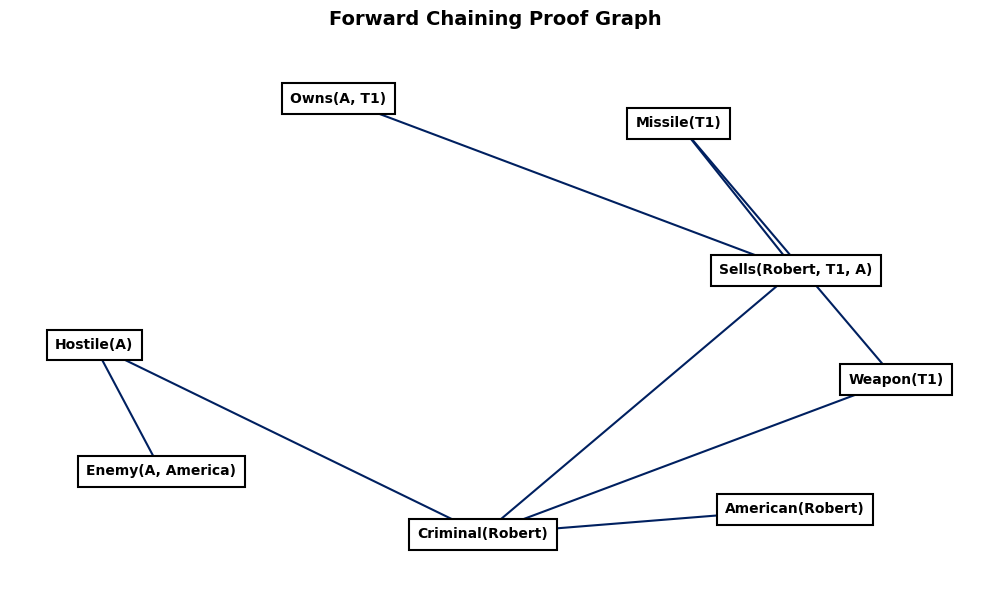

In [4]:
import re
import matplotlib.pyplot as plt
import networkx as nx

# --- FOL Representation & Helpers ---

class Variable:
    def __init__(self, name):
        self.name = name
    def __repr__(self):
        return f"?{self.name}"
    def __eq__(self, other):
        return isinstance(other, Variable) and self.name == other.name
    def __hash__(self):
        return hash(self.name)

class Expr:
    def __init__(self, op, *args):
        self.op = op
        self.args = tuple(args)
    def __repr__(self):
        if not self.args:
            return str(self.op)
        return f"{self.op}({', '.join(map(str, self.args))})"
    def __eq__(self, other):
        return isinstance(other, Expr) and self.op == other.op and self.args == other.args
    def __hash__(self):
        return hash((self.op, self.args))

class Clause:
    def __init__(self, body, head):
        self.body = body  # List of Expr
        self.head = head  # Single Expr
    def __repr__(self):
        if not self.body:
            return f"{self.head}"
        return f"{' & '.join(map(str, self.body))} => {self.head}"

def is_variable(x):
    return isinstance(x, Variable)

def subst(theta, expr):
    """Applies substitution theta to an expression."""
    if is_variable(expr):
        return theta.get(expr, expr)
    if isinstance(expr, Expr):
        return Expr(expr.op, *[subst(theta, arg) for arg in expr.args])
    return expr

def unify(x, y, theta=None):
    """Unifies expressions x and y under substitution theta."""
    if theta is None:
        theta = {}
    if theta is False:
        return False
    if x == y:
        return theta
    if is_variable(x):
        return unify_var(x, y, theta)
    if is_variable(y):
        return unify_var(y, x, theta)
    if isinstance(x, Expr) and isinstance(y, Expr):
        if x.op != y.op or len(x.args) != len(y.args):
            return False
        for ax, ay in zip(x.args, y.args):
            theta = unify(ax, ay, theta)
            if theta is False:
                return False
        return theta
    return False

def unify_var(var, val, theta):
    if var in theta:
        return unify(theta[var], val, theta)
    if val in theta:
        return unify(var, theta[val], theta)
    new_theta = theta.copy()
    new_theta[var] = val
    return new_theta

# --- Variable Standardizer ---
var_counter = 0
def standardize_variables(clause):
    global var_counter
    var_map = {}

    def collect_and_rename(expr):
        global var_counter
        if is_variable(expr):
            if expr not in var_map:
                var_counter += 1
                var_map[expr] = Variable(f"{expr.name}_{var_counter}")
            return var_map[expr]
        if isinstance(expr, Expr):
            return Expr(expr.op, *[collect_and_rename(arg) for arg in expr.args])
        return expr

    new_body = [collect_and_rename(b) for b in clause.body]
    new_head = collect_and_rename(clause.head)
    return Clause(new_body, new_head)

# --- String Parsing Helpers ---

def parse_expr(s):
    """Parses a string like 'Predicate(arg1, arg2)' into an Expr object."""
    s = s.strip()
    match = re.match(r"^([A-Za-z0-9_]+)\((.*)\)$", s)
    if not match:
        # If it's a standalone term (argument inside parentheses)
        if s and s[0].islower():
            return Variable(s)
        return s

    op = match.group(1)
    args_str = match.group(2).strip()
    if not args_str:
        args = []
    else:
        args = [parse_expr(arg.strip()) for arg in args_str.split(',')]
    return Expr(op, *args)

def parse_clause(s):
    """Parses a full rule 'P1(x) & P2(y) => Q(x)' or a fact 'P1(A)' into a Clause."""
    s = s.strip()
    if "=>" in s:
        body_str, head_str = s.split("=>")
        body_parts = body_str.split("&")
        body = [parse_expr(part) for part in body_parts]
        head = parse_expr(head_str)
        return Clause(body, head)
    else:
        head = parse_expr(s)
        return Clause([], head)

# --- Forward Chaining Algorithm ---

def match_body(index, current_theta, rules_body, facts, trigger_facts):
    """Recursive generator matching rule premises to KB facts while tracking triggers."""
    if index == len(rules_body):
        yield current_theta, list(trigger_facts)
        return
    p_i = rules_body[index]
    for fact in facts:
        theta_i = unify(p_i, fact, current_theta)
        if theta_i is not False:
            trigger_facts.append(fact)
            yield from match_body(index + 1, theta_i, rules_body, facts, trigger_facts)
            trigger_facts.pop()

def fol_fc_ask(KB, alpha):
    """Implements FOL-FC-ASK with unified dependency edge logging for graphics."""
    graph_edges = []
    facts = set()
    rules = []

    for clause in KB:
        if not clause.body:
            facts.add(clause.head)
        else:
            rules.append(clause)

    while True:
        new = set()
        for rule in rules:
            standard_rule = standardize_variables(rule)
            p_list = standard_rule.body
            q = standard_rule.head

            for theta, trigger_facts in match_body(0, {}, p_list, facts, []):
                q_prime = subst(theta, q)

                already_exists = any(unify(q_prime, f) is not False for f in facts.union(new))
                if not already_exists:
                    new.add(q_prime)

                    rule_label = f"{' & '.join(p.op for p in rule.body)} => {rule.head.op}"
                    for tf in trigger_facts:
                        graph_edges.append((str(tf), str(q_prime), rule_label))

                    phi = unify(q_prime, alpha)
                    if phi is not False:
                        facts.update(new)
                        return phi, graph_edges

        if not new:
            break
        facts.update(new)

    return False, graph_edges

def plot_forward_chaining_graph(edges):
    """Renders a clean, slide-style graph with box nodes and no text descriptions over the paths."""
    if not edges:
        print("\n[Visualizer] No deduction paths triggered to display.")
        return

    G = nx.DiGraph()
    for u, v, _ in edges:
        G.add_edge(u, v)

    plt.figure(figsize=(10, 6))

    # Generate spatial positioning coordinates
    pos = nx.spring_layout(G, k=1.8, seed=42)

    # Draw transparent nodes so the text boxes act as the actual node boundaries
    nx.draw_networkx_nodes(G, pos, node_size=0, node_color="none")

    # Draw clean directional paths pointing down toward the conclusions
    nx.draw_networkx_edges(
        G, pos,
        arrowstyle="-|>",
        arrowsize=18,
        edge_color="#002060",  # Dark blue slide style arrows
        width=1.5,
        node_size=0
    )

    # Overlay clean text block box nodes
    for node, (x, y) in pos.items():
        plt.text(
            x, y, node,
            fontsize=10,
            fontweight='bold',
            ha='center',
            va='center',
            bbox=dict(
                boxstyle="square,pad=0.6",
                facecolor="white",
                edgecolor="black",
                lw=1.5
            )
        )

    plt.title("Forward Chaining Proof Graph", fontsize=14, fontweight='bold', pad=20)
    plt.axis('off')
    plt.tight_layout()
    plt.show()


# --- Interactive Terminal Workflow ---
if __name__ == "__main__":
    KB = []
    print("=======================================================")
    print("  FOL FORWARD CHAINING SOLVER WITH INTERACTIVE PARSER  ")
    print("=======================================================\n")

    print("--- Step 1: Enter Facts & Rules (Leave empty and press Enter when done) ---")
    print("Example Fact: American(West)")
    print("Example Rule: Owns(Nono, y) & Missile(y) => Sells(West, y, Nono)\n")

    count = 1
    while True:
        line = input(f"Input Statement #{count}: ").strip()
        if not line:
            break
        try:
            parsed_clause = parse_clause(line)
            KB.append(parsed_clause)
            count += 1
        except Exception as e:
            print(f"❌ Error parsing input line. Please check syntax rules. ({e})")

    if not KB:
        print("Knowledge base is empty. Exiting.")
        exit()

    print("\n--- Step 2: Enter the Query ---")
    print("Example Query: Criminal(West)")
    while True:
        query_line = input("Query: ").strip()
        if query_line:
            try:
                query_expr = parse_expr(query_line)
                break
            except Exception as e:
                print(f"❌ Error parsing query. ({e})")

    print("\n[Status] Running Forward Chaining Inference Engine...")
    result, deduction_edges = fol_fc_ask(KB, query_expr)

    print("\n=================== RESULTS ===================")
    if result is not False:
        print(f"✅ SUCCESS: Query is TRUE!")
        print(f"Substitution Bindings (Theta): {result}")
    else:
        print("❌ FAILED: Query cannot be derived from the provided Knowledge Base.")

    print("\nDeduction Paths Discovered:")
    if deduction_edges:
        for parent, child, rule in deduction_edges:
            print(f"  [{parent}] ---({rule})---> [{child}]")
    else:
        print("  (None)")
    print("===============================================")

    # Render interactive map window
    plot_forward_chaining_graph(deduction_edges)


In [5]:
import re

# --- FOL Representation & Helpers ---

class Variable:
    def __init__(self, name):
        self.name = name
    def __repr__(self):
        return f"?{self.name}"
    def __eq__(self, other):
        return isinstance(other, Variable) and self.name == other.name
    def __hash__(self):
        return hash(self.name)

class Expr:
    def __init__(self, op, *args):
        self.op = op
        self.args = tuple(args)
    def __repr__(self):
        if not self.args:
            return str(self.op)
        return f"{self.op}({', '.join(map(str, self.args))})"
    def __eq__(self, other):
        return isinstance(other, Expr) and self.op == other.op and self.args == other.args
    def __hash__(self):
        return hash((self.op, self.args))

class Clause:
    def __init__(self, body, head):
        self.body = body  # List of Expr
        self.head = head  # Single Expr
    def __repr__(self):
        if not self.body:
            return f"{self.head}"
        return f"{' & '.join(map(str, self.body))} => {self.head}"

def is_variable(x):
    return isinstance(x, Variable)

def subst(theta, expr):
    """Applies substitution theta to an expression."""
    if is_variable(expr):
        return theta.get(expr, expr)
    if isinstance(expr, Expr):
        return Expr(expr.op, *[subst(theta, arg) for arg in expr.args])
    return expr

def unify(x, y, theta=None):
    """Unifies expressions x and y under substitution theta."""
    if theta is None:
        theta = {}
    if theta is False:
        return False
    if x == y:
        return theta
    if is_variable(x):
        return unify_var(x, y, theta)
    if is_variable(y):
        return unify_var(y, x, theta)
    if isinstance(x, Expr) and isinstance(y, Expr):
        if x.op != y.op or len(x.args) != len(y.args):
            return False
        for ax, ay in zip(x.args, y.args):
            theta = unify(ax, ay, theta)
            if theta is False:
                return False
        return theta
    return False

def unify_var(var, val, theta):
    if var in theta:
        return unify(theta[var], val, theta)
    if val in theta:
        return unify(var, theta[val], theta)
    new_theta = theta.copy()
    new_theta[var] = val
    return new_theta

# --- Variable Standardizer ---
var_counter = 0
def standardize_variables(clause):
    global var_counter
    var_map = {}

    def collect_and_rename(expr):
        global var_counter
        if is_variable(expr):
            if expr not in var_map:
                var_counter += 1
                var_map[expr] = Variable(f"{expr.name}_{var_counter}")
            return var_map[expr]
        if isinstance(expr, Expr):
            return Expr(expr.op, *[collect_and_rename(arg) for arg in expr.args])
        return expr

    new_body = [collect_and_rename(b) for b in clause.body]
    new_head = collect_and_rename(clause.head)
    return Clause(new_body, new_head)

# --- String Parsing Helpers ---

def parse_expr(s):
    """Parses a string like 'Predicate(arg1, arg2)' into an Expr object."""
    s = s.strip()
    match = re.match(r"^([A-Za-z0-9_]+)\((.*)\)$", s)
    if not match:
        if s and s[0].islower():
            return Variable(s)
        return s

    op = match.group(1)
    args_str = match.group(2).strip()
    if not args_str:
        args = []
    else:
        args = [parse_expr(arg.strip()) for arg in args_str.split(',')]
    return Expr(op, *args)

def parse_clause(s):
    """Parses a full rule 'P1(x) & P2(y) => Q(x)' or a fact 'P1(A)' into a Clause."""
    s = s.strip()
    if "=>" in s:
        body_str, head_str = s.split("=>")
        body_parts = body_str.split("&")
        body = [parse_expr(part) for part in body_parts]
        head = parse_expr(head_str)
        return Clause(body, head)
    else:
        head = parse_expr(s)
        return Clause([], head)

# --- Forward Chaining Algorithm ---

def match_body(index, current_theta, rules_body, facts, trigger_facts):
    """Recursive generator matching rule premises to KB facts while tracking triggers."""
    if index == len(rules_body):
        yield current_theta, list(trigger_facts)
        return
    p_i = rules_body[index]
    for fact in facts:
        theta_i = unify(p_i, fact, current_theta)
        if theta_i is not False:
            trigger_facts.append(fact)
            yield from match_body(index + 1, theta_i, rules_body, facts, trigger_facts)
            trigger_facts.pop()

def fol_fc_ask(KB, alpha):
    """Implements FOL-FC-ASK and logs dependency edges for console tracking."""
    graph_edges = []
    facts = set()
    rules = []

    for clause in KB:
        if not clause.body:
            facts.add(clause.head)
        else:
            rules.append(clause)

    while True:
        new = set()
        for rule in rules:
            standard_rule = standardize_variables(rule)
            p_list = standard_rule.body
            q = standard_rule.head

            for theta, trigger_facts in match_body(0, {}, p_list, facts, []):
                q_prime = subst(theta, q)

                already_exists = any(unify(q_prime, f) is not False for f in facts.union(new))
                if not already_exists:
                    new.add(q_prime)

                    rule_label = f"{' & '.join(p.op for p in rule.body)} => {rule.head.op}"
                    for tf in trigger_facts:
                        graph_edges.append((str(tf), str(q_prime), rule_label))

                    phi = unify(q_prime, alpha)
                    if phi is not False:
                        facts.update(new)
                        return phi, graph_edges

        if not new:
            break
        facts.update(new)

    return False, graph_edges

# --- Interactive Terminal Workflow ---
if __name__ == "__main__":
    KB = []
    print("=======================================================")
    print("  FOL FORWARD CHAINING SOLVER WITH INTERACTIVE PARSER  ")
    print("=======================================================\n")

    print("--- Step 1: Enter Facts & Rules (Leave empty and press Enter when done) ---")
    print("Example Fact: American(West)")
    print("Example Rule: Owns(Nono, y) & Missile(y) => Sells(West, y, Nono)\n")

    count = 1
    while True:
        line = input(f"Input Statement #{count}: ").strip()
        if not line:
            break
        try:
            parsed_clause = parse_clause(line)
            KB.append(parsed_clause)
            count += 1
        except Exception as e:
            print(f"❌ Error parsing input line. Please check syntax rules. ({e})")

    if not KB:
        print("Knowledge base is empty. Exiting.")
        exit()

    print("\n--- Step 2: Enter the Query ---")
    print("Example Query: Criminal(West)")
    while True:
        query_line = input("Query: ").strip()
        if query_line:
            try:
                query_expr = parse_expr(query_line)
                break
            except Exception as e:
                print(f"❌ Error parsing query. ({e})")

    print("\n[Status] Running Forward Chaining Inference Engine...")
    result, deduction_edges = fol_fc_ask(KB, query_expr)

    print("\n=================== RESULTS ===================")
    if result is not False:
        print(f"✅ SUCCESS: Query is TRUE!")
        print(f"Substitution Bindings (Theta): {result}")
    else:
        print("❌ FAILED: Query cannot be derived from the provided Knowledge Base.")

    print("\nDeduction Paths Discovered:")
    if deduction_edges:
        for parent, child, rule in deduction_edges:
            print(f"  [{parent}] ---({rule})---> [{child}]")
    else:
        print("  (None)")
    print("===============================================")


  FOL FORWARD CHAINING SOLVER WITH INTERACTIVE PARSER  

--- Step 1: Enter Facts & Rules (Leave empty and press Enter when done) ---
Example Fact: American(West)
Example Rule: Owns(Nono, y) & Missile(y) => Sells(West, y, Nono)

Input Statement #1: American(Robert)
Input Statement #2: Enemy(A, America)
Input Statement #3: Owns(A, T1)
Input Statement #4: Missile(T1)
Input Statement #5: Missile(x) => Weapon(x)
Input Statement #6: Enemy(x, America) => Hostile(x)
Input Statement #7: Missile(x) & Owns(A, x) => Sells(Robert, x, A)
Input Statement #8: American(p) & Weapon(q) & Sells(p, q, r) & Hostile(r) => Criminal(p)
Input Statement #9: 

--- Step 2: Enter the Query ---
Example Query: Criminal(West)
Query: Criminal(Robert)

[Status] Running Forward Chaining Inference Engine...

=================== RESULTS ===================
✅ SUCCESS: Query is TRUE!
Substitution Bindings (Theta): {}

Deduction Paths Discovered:
  [Missile(T1)] ---(Missile => Weapon)---> [Weapon(T1)]
  [Enemy(A, America)] --